# Modularity on the Karate Club Graph
**DSC212 Assignment**

This notebook applies recursive spectral modularity partitioning to Zachary's Karate Club graph. It visualizes the communities and studies how network metrics change after each split.

## 1. Introduction
In this assignment, we study community detection using the Karate Club graph, a social network with 34 nodes and 78 edges.

Our aim is to divide the network into smaller communities using the spectral modularity method. We also calculate degree centrality, betweenness centrality, closeness centrality and clustering coefficient. Finally, we use graphs and heatmaps to understand how these measures change when the network is divided.

## 2. Importing Required Libraries

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

## 3. Loading the Karate Club Graph

In [2]:
G_original = nx.karate_club_graph()
print("Number of nodes:", G_original.number_of_nodes())
print("Number of edges:", G_original.number_of_edges())
G_working = G_original.copy()

Number of nodes: 34
Number of edges: 78


## 4. Visualizing the Original Graph

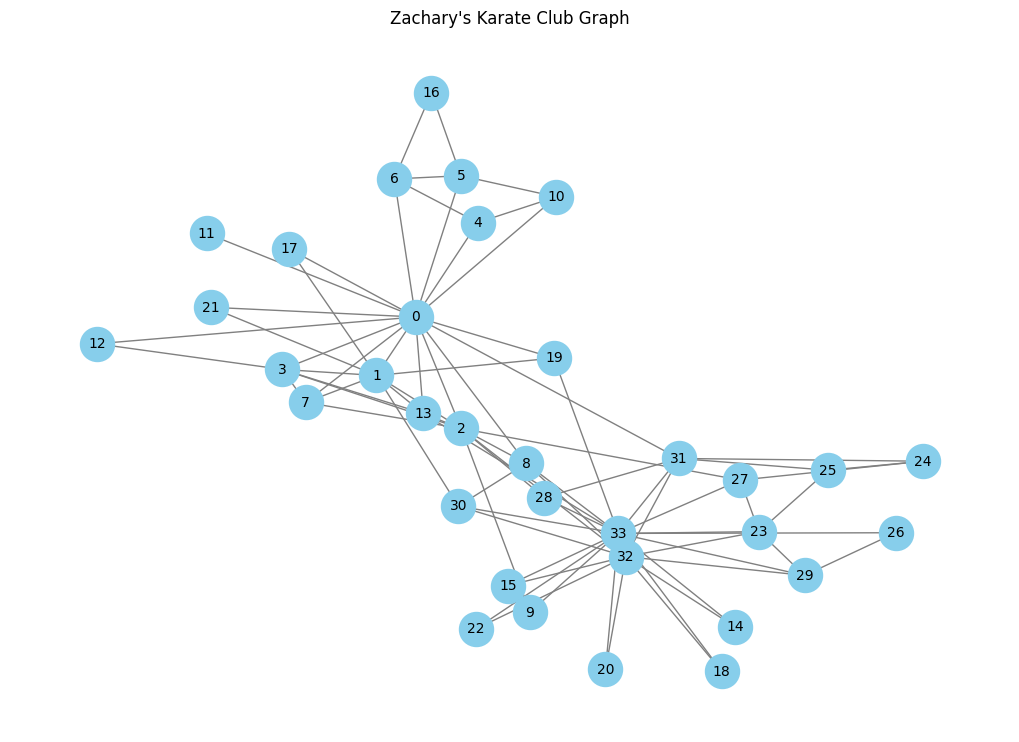

In [3]:
pos = nx.spring_layout(G_original, seed=42)
plt.figure(figsize=(10, 7))
nx.draw(G_original, pos, with_labels=True, node_color="skyblue",
        node_size=600, font_size=10, edge_color="gray")
plt.title("Zachary's Karate Club Graph")
plt.show()

## 5. Constructing the Modularity Matrix

The modularity matrix is

\[
B = A - \frac{kk^T}{2m},
\]

where \(A\) is the unweighted adjacency matrix, \(k\) is the vector of node degrees, and \(m\) is the total number of edges.

In [4]:
# weight=None makes the adjacency matrix unweighted (0 or 1).
A = nx.to_numpy_array(G_original, weight=None)
k = np.sum(A, axis=1)
m = G_original.number_of_edges()
B = A - np.outer(k, k) / (2 * m)

print("Adjacency matrix shape:", A.shape)
print("Sum of degrees:", int(np.sum(k)))
print("Number of edges:", m)
print("Modularity matrix shape:", B.shape)

Adjacency matrix shape: (34, 34)
Sum of degrees: 156
Number of edges: 78
Modularity matrix shape: (34, 34)


## 6. Recursive Spectral Modularity Partitioning

For each community, we take the corresponding block of the original global modularity matrix. We find its largest eigenvalue and eigenvector.

- If the largest eigenvalue is positive, split the community according to the signs of the eigenvector entries.
- If the largest eigenvalue is zero or negative, stop splitting that community.
- Repeat until no further community can be split.

The original degree vector and original edge count are retained in the modularity matrix.

In [5]:
# Begin with the entire graph as one community.
communities = [list(G_original.nodes())]
partition_history = [[c.copy() for c in communities]]
split_eigenvalues = []

# Keep trying to split communities until no valid split remains.
while True:
    split_made = False

    for community in communities.copy():
        B_sub = B[np.ix_(community, community)]
        eigenvalues, eigenvectors = np.linalg.eigh(B_sub)
        index = np.argmax(eigenvalues)
        largest_eigenvalue = eigenvalues[index]
        split_eigenvalues.append(largest_eigenvalue)

        if largest_eigenvalue <= 1e-10:
            continue

        leading_vector = eigenvectors[:, index]
        group_1 = [community[i] for i in range(len(community))
                   if leading_vector[i] > 0]
        group_2 = [community[i] for i in range(len(community))
                   if leading_vector[i] <= 0]

        if len(group_1) == 0 or len(group_2) == 0:
            continue

        communities.remove(community)
        communities.extend([group_1, group_2])
        partition_history.append([c.copy() for c in communities])
        split_made = True
        break

    if not split_made:
        break

print("Total number of communities:", len(communities))
for i, community in enumerate(communities, start=1):
    print(f"Community {i}: {community}")

Total number of communities: 5
Community 1: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 2: [24, 25, 27, 28, 31]
Community 3: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Community 4: [11]
Community 5: [4, 5, 6, 10, 16]


## 7. Visualizing the Graph After Each Split

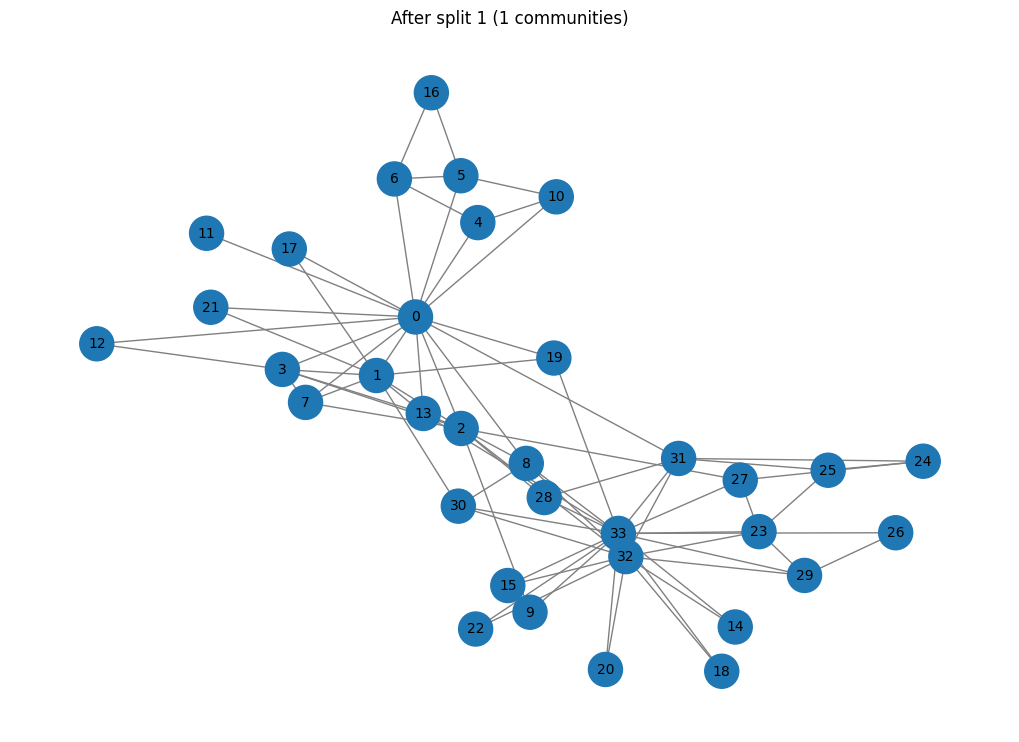

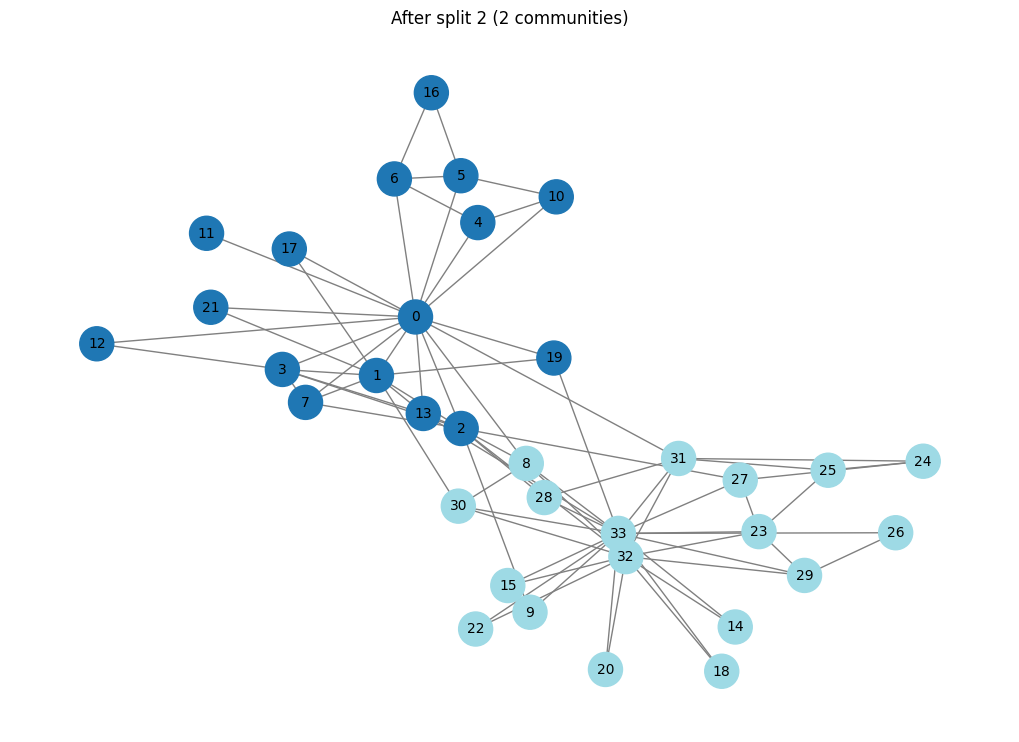

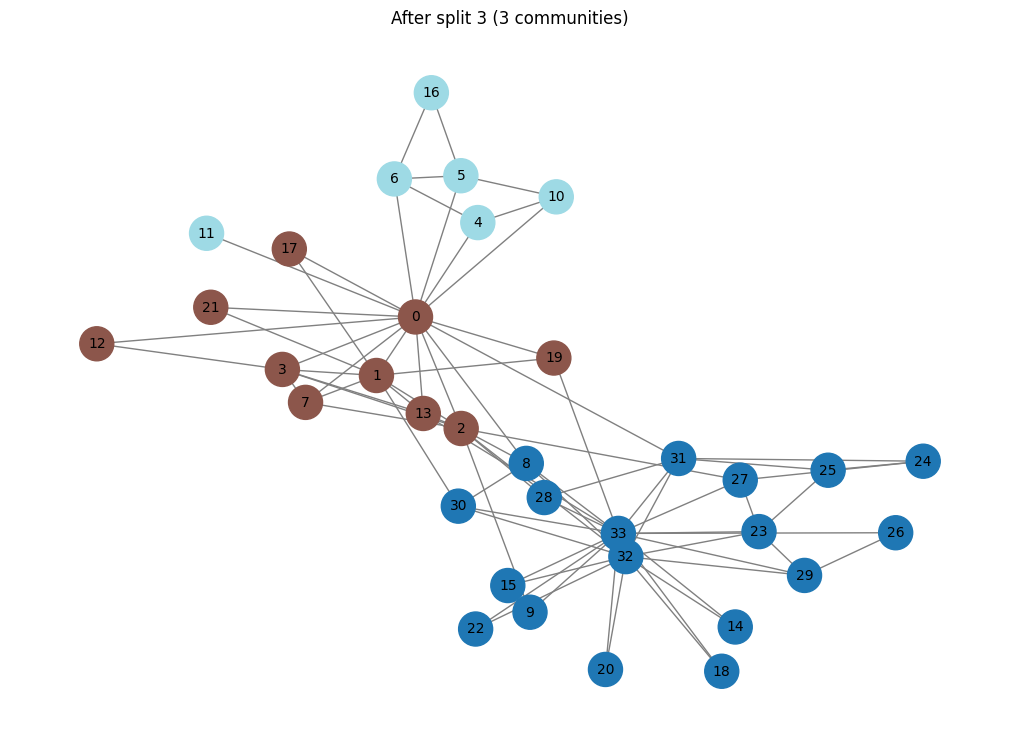

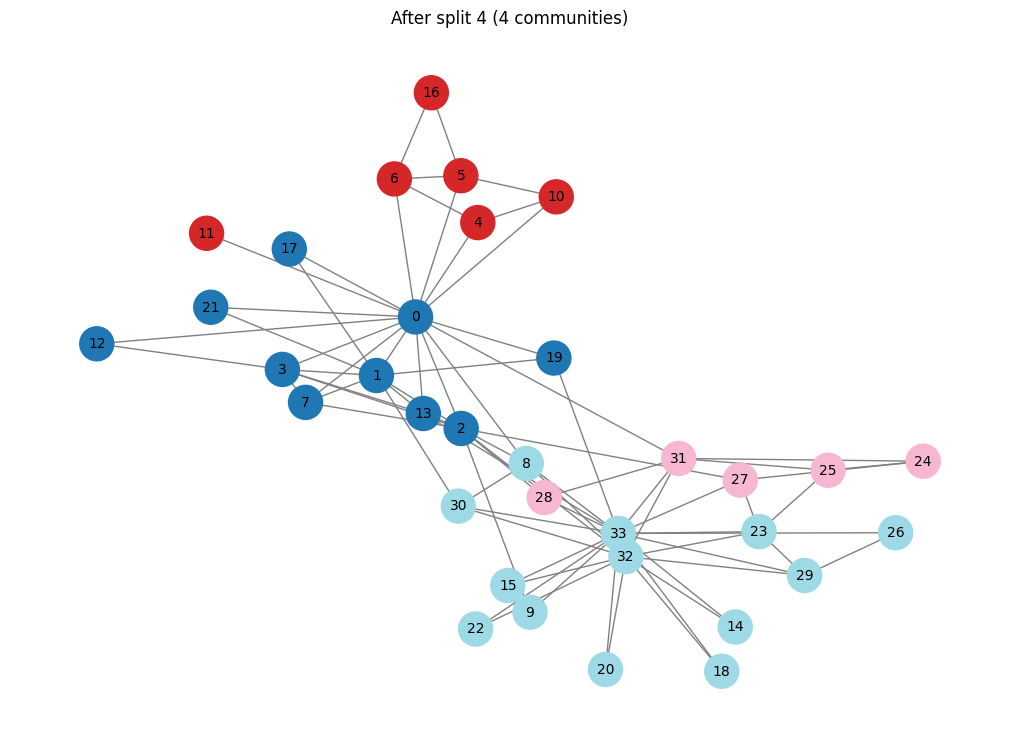

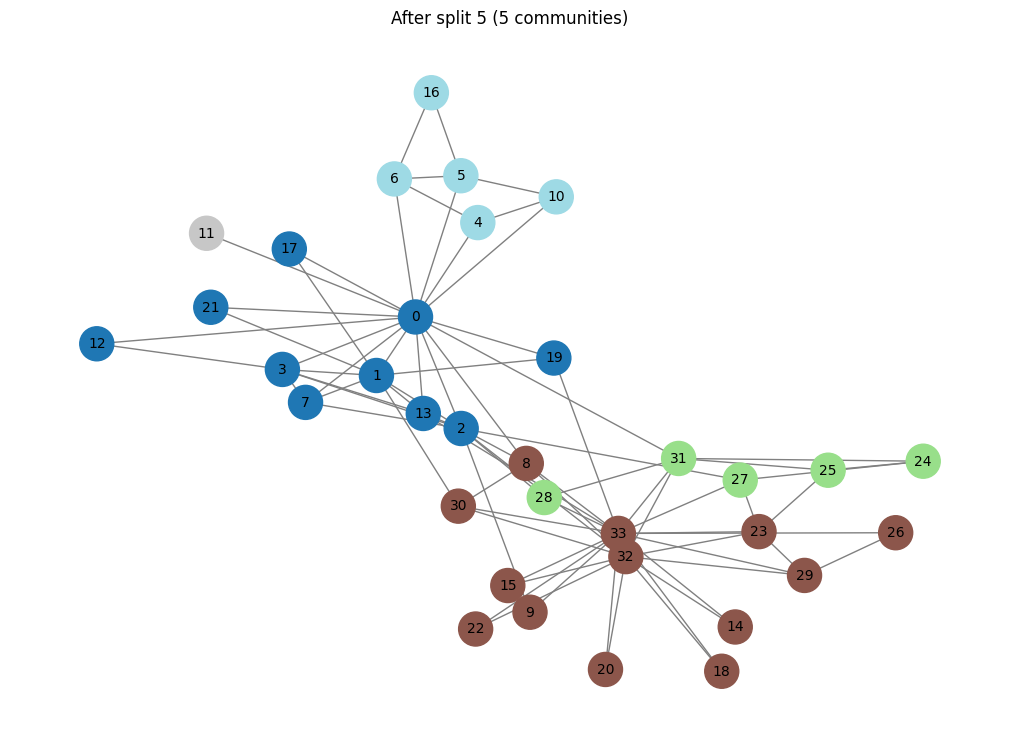

In [6]:
for iteration, partition in enumerate(partition_history, start=1):
    node_colors = [0] * G_original.number_of_nodes()
    for community_id, community in enumerate(partition):
        for node in community:
            node_colors[node] = community_id

    plt.figure(figsize=(10, 7))
    nx.draw(G_original, pos, with_labels=True, node_color=node_colors,
            cmap=plt.cm.tab20, node_size=600, font_size=10,
            edge_color="gray")
    plt.title(f"After split {iteration} ({len(partition)} communities)")
    plt.show()

## 8. Calculation of Network Metrics

After each split, the metrics are calculated on each community's induced subgraph. This shows how a node's position within its own community changes as the partition becomes finer.

In [7]:
metrics_history = {
    "Degree Centrality": [],
    "Betweenness Centrality": [],
    "Closeness Centrality": [],
    "Clustering Coefficient": []
}

for partition in partition_history:
    degree_values = {}
    betweenness_values = {}
    closeness_values = {}
    clustering_values = {}

    for community in partition:
        subgraph = G_original.subgraph(community).copy()
        degree_values.update(nx.degree_centrality(subgraph))
        betweenness_values.update(nx.betweenness_centrality(subgraph))
        closeness_values.update(nx.closeness_centrality(subgraph))
        clustering_values.update(nx.clustering(subgraph))

    metrics_history["Degree Centrality"].append(degree_values)
    metrics_history["Betweenness Centrality"].append(betweenness_values)
    metrics_history["Closeness Centrality"].append(closeness_values)
    metrics_history["Clustering Coefficient"].append(clustering_values)

print("Network metrics calculated successfully!")
print("Number of recorded partitions:", len(partition_history))
print("Number of nodes:", G_original.number_of_nodes())

Network metrics calculated successfully!
Number of recorded partitions: 5
Number of nodes: 34


## 9. Evolution of Network Metrics

##9.1 Heatmaps

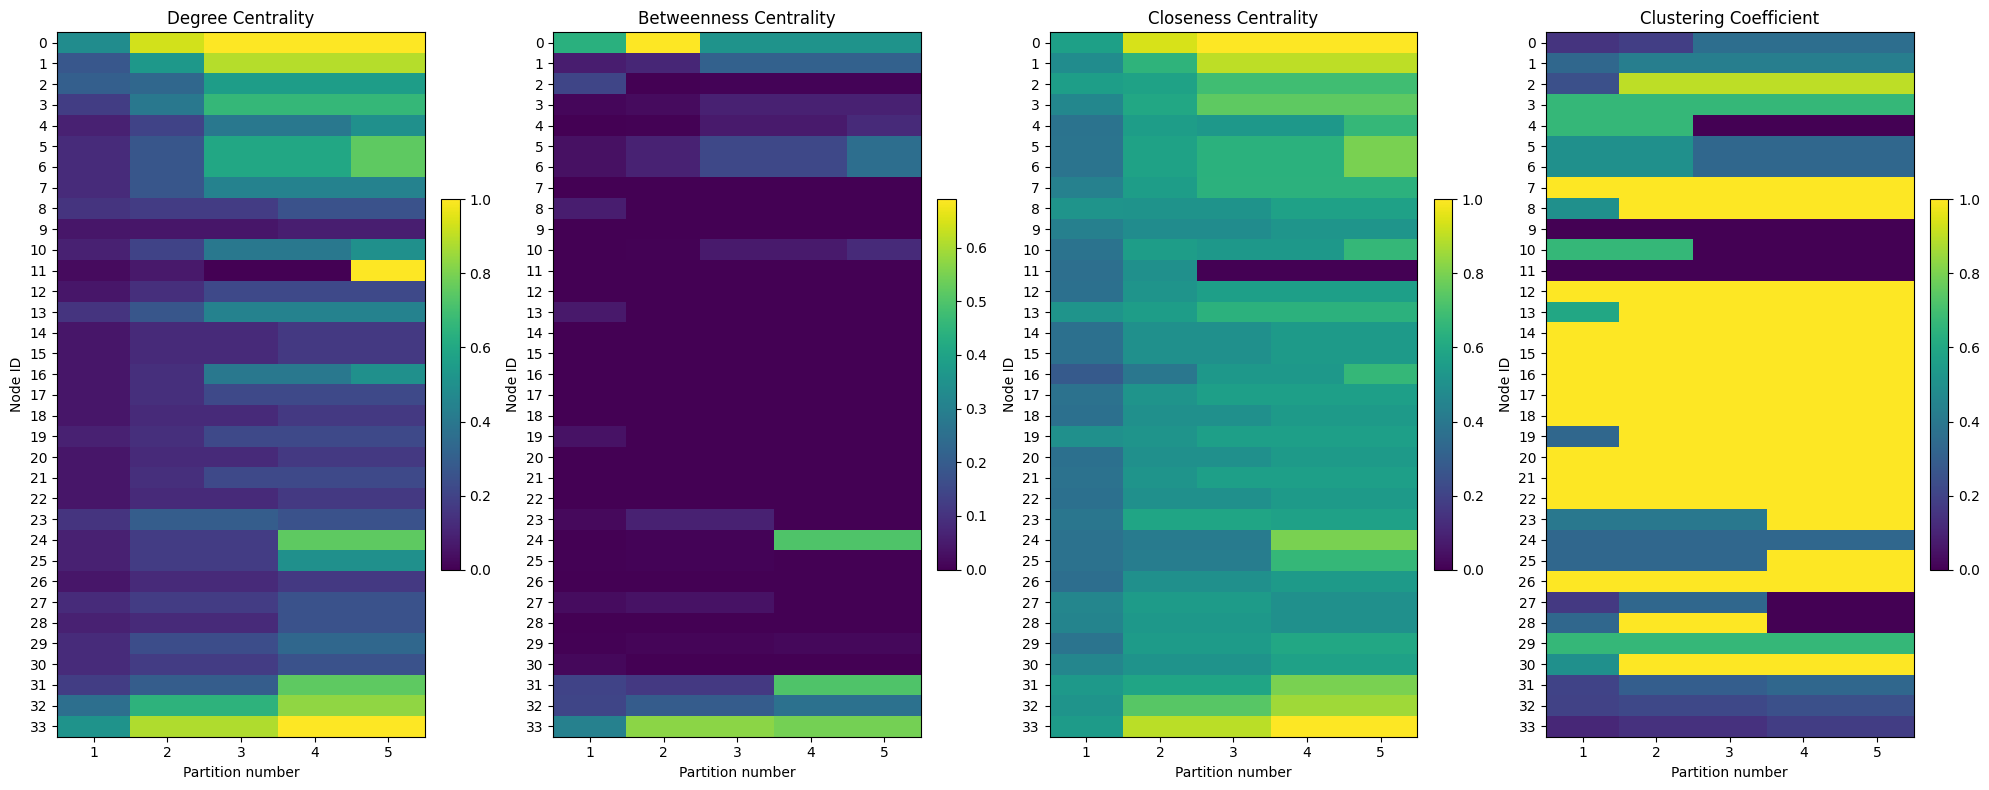

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 8))
for ax, (metric_name, metric_data) in zip(axes, metrics_history.items()):
    data = np.array([[iteration[node] for iteration in metric_data]
                     for node in G_original.nodes()])
    im = ax.imshow(data, aspect="auto", cmap="viridis")
    ax.set_title(metric_name)
    ax.set_xlabel("Partition number")
    ax.set_ylabel("Node ID")
    ax.set_xticks(range(len(partition_history)))
    ax.set_xticklabels(range(1, len(partition_history) + 1))
    ax.set_yticks(range(G_original.number_of_nodes()))
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### 9.2 Line Graphs for All Nodes

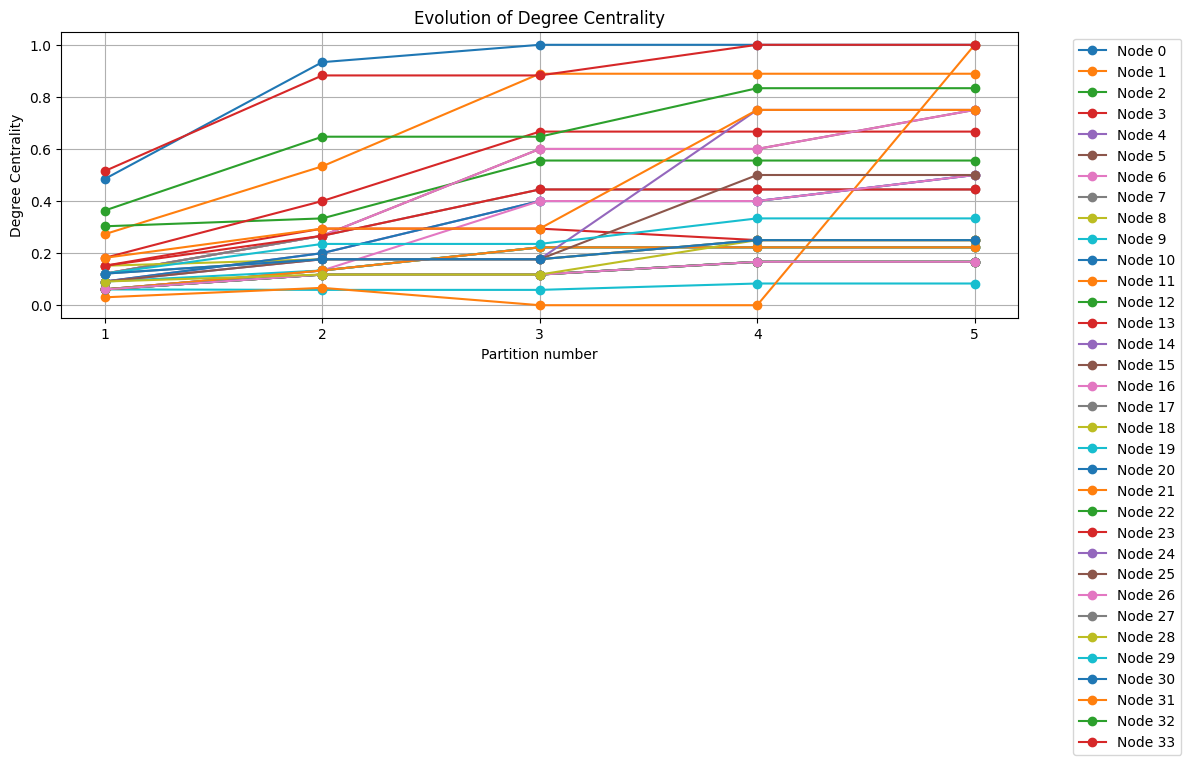

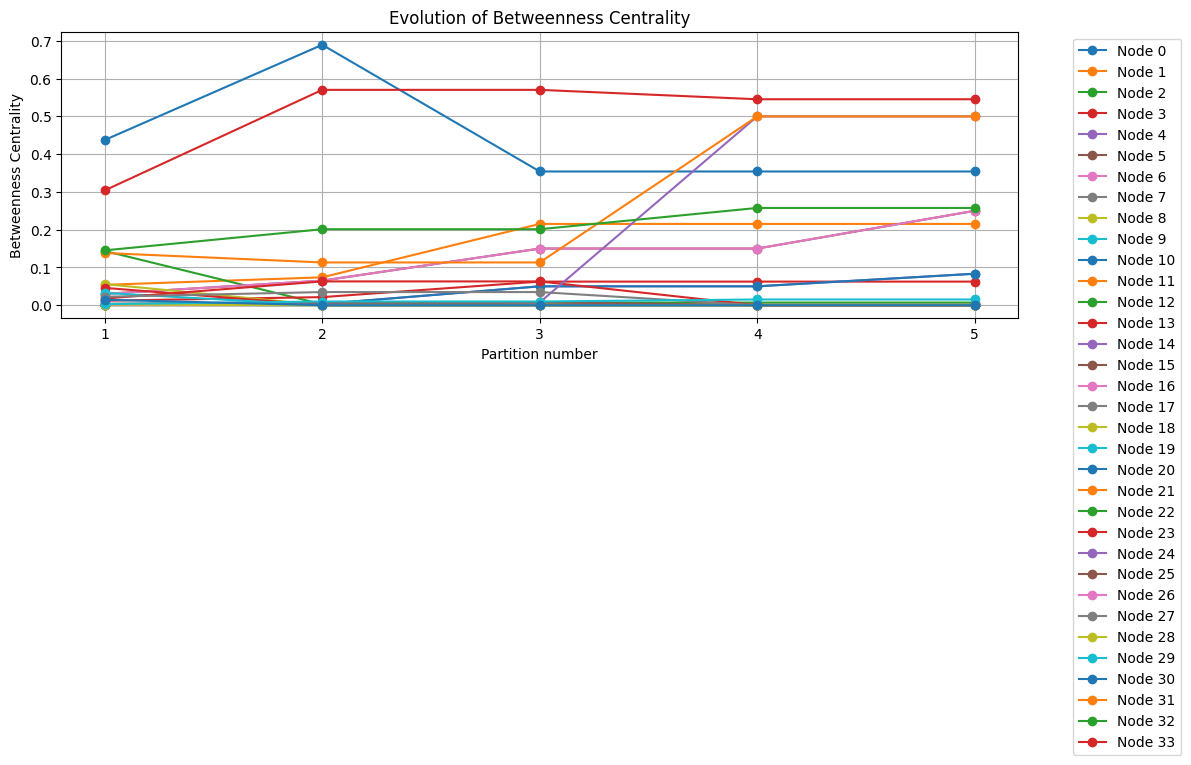

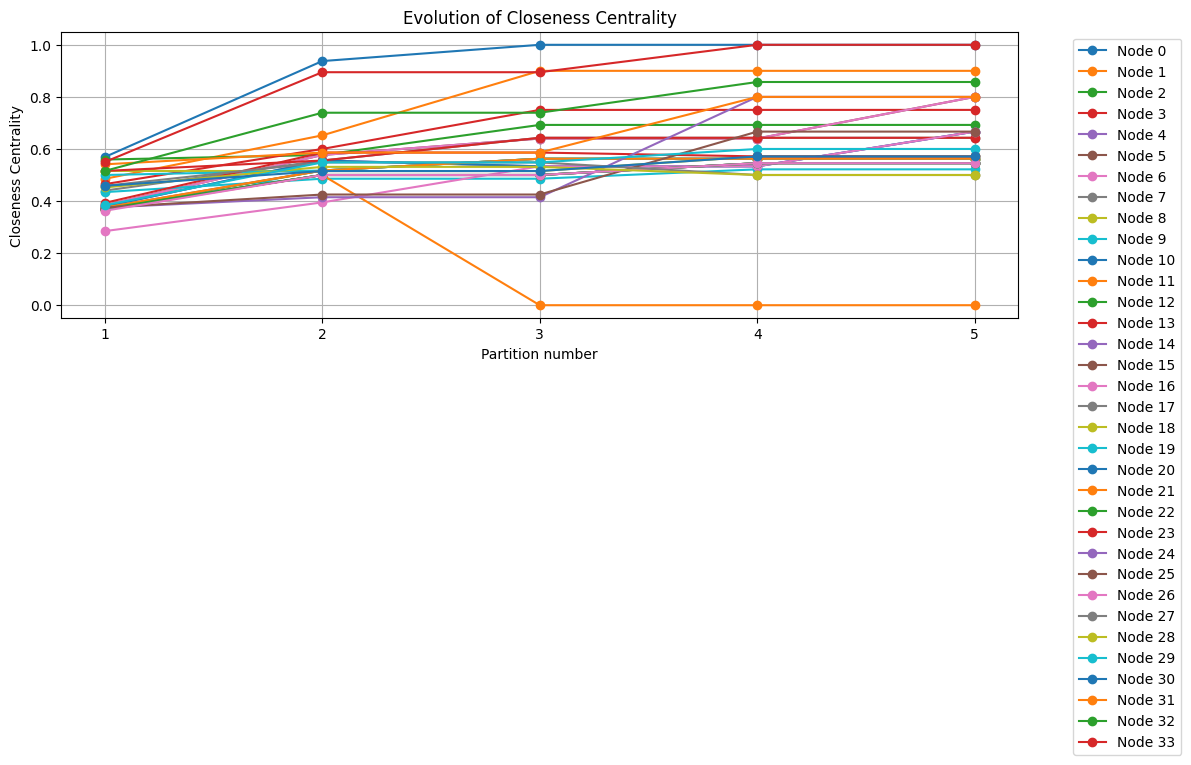

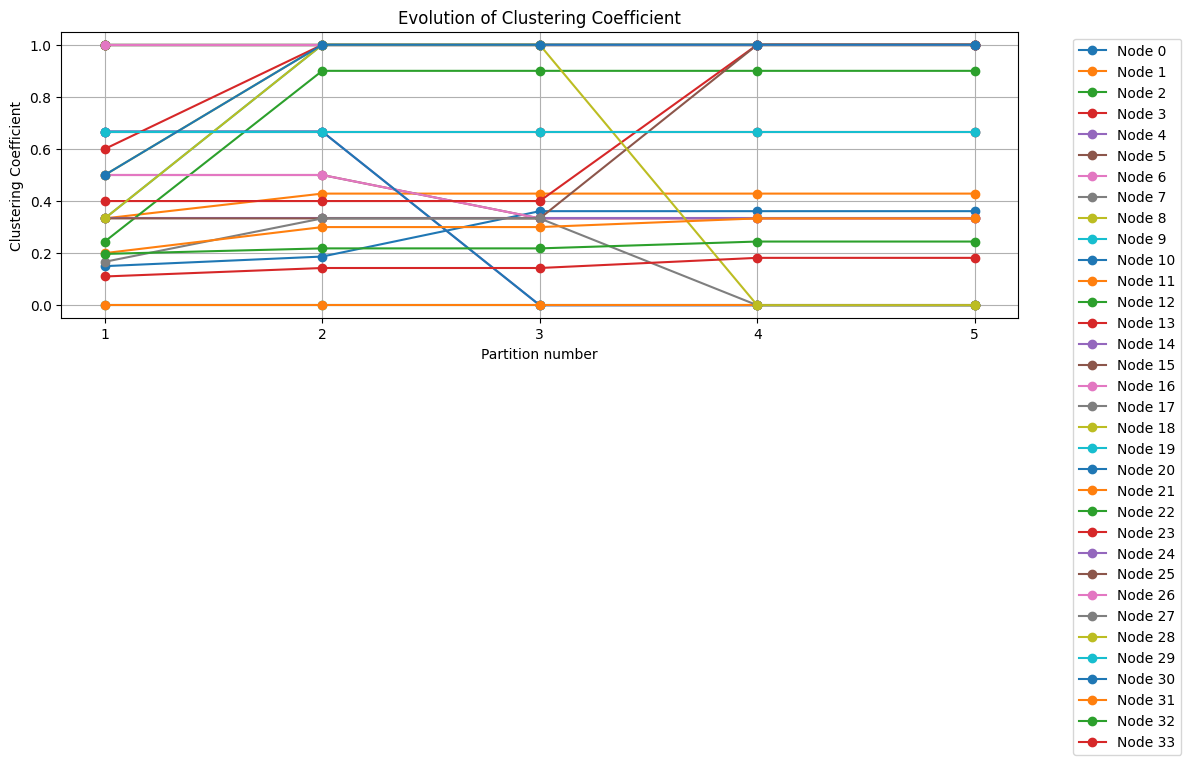

In [9]:
for metric_name, metric_data in metrics_history.items():
    plt.figure(figsize=(12, 6))
    for node in G_original.nodes():
        values = [iteration[node] for iteration in metric_data]
        plt.plot(range(1, len(values) + 1), values,
                 marker="o", label=f"Node {node}")
    plt.title(f"Evolution of {metric_name}")
    plt.xlabel("Partition number")
    plt.ylabel(metric_name)
    plt.xticks(range(1, len(partition_history) + 1))
    plt.grid(True)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

### 9.3 Line Graphs Highlighting the Five Highest-Average Nodes

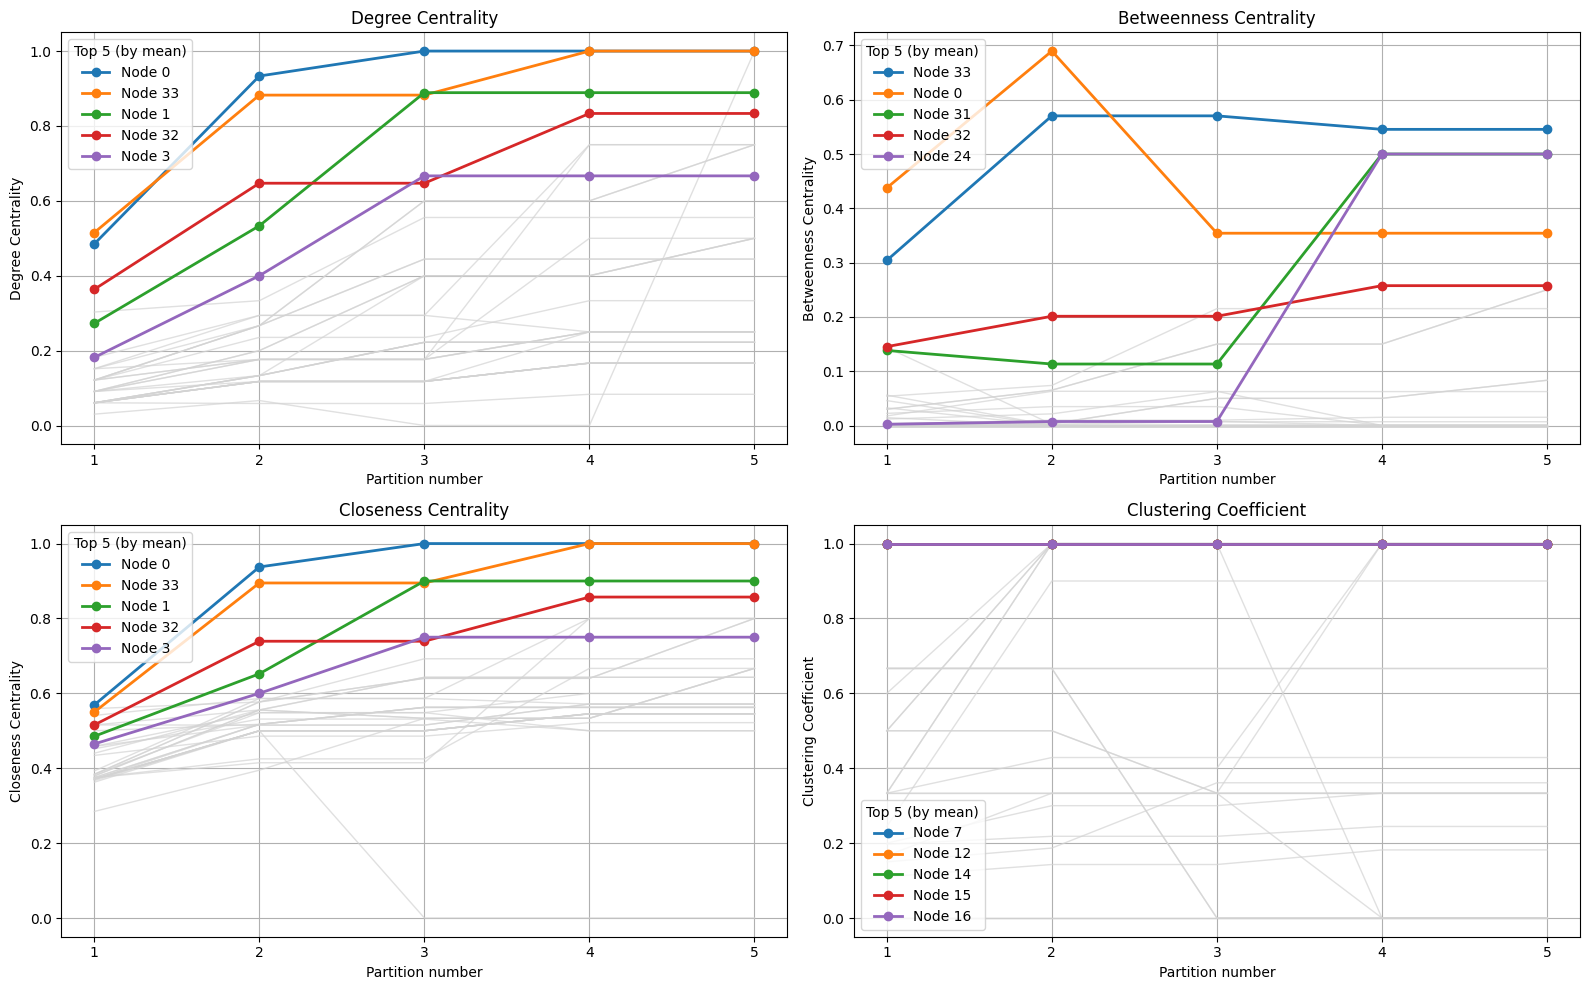

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, (metric_name, metric_data) in zip(axes, metrics_history.items()):
    average_values = {
        node: np.mean([iteration[node] for iteration in metric_data])
        for node in G_original.nodes()
    }
    top_nodes = sorted(average_values, key=average_values.get,
                       reverse=True)[:5]

    for node in G_original.nodes():
        if node not in top_nodes:
            values = [iteration[node] for iteration in metric_data]
            ax.plot(range(1, len(values) + 1), values,
                    color="lightgray", alpha=0.7, linewidth=1)

    for node in top_nodes:
        values = [iteration[node] for iteration in metric_data]
        ax.plot(range(1, len(values) + 1), values,
                marker="o", linewidth=2, label=f"Node {node}")

    ax.set_title(metric_name)
    ax.set_xlabel("Partition number")
    ax.set_ylabel(metric_name)
    ax.set_xticks(range(1, len(partition_history) + 1))
    ax.grid(True)
    ax.legend(title="Top 5 (by mean)")
plt.tight_layout()
plt.show()

## 10. Top Five Nodes for Each Metric

In [11]:
for metric_name, metric_data in metrics_history.items():
    average_values = {
        node: np.mean([iteration[node] for iteration in metric_data])
        for node in G_original.nodes()
    }
    top_nodes = sorted(average_values.items(),
                       key=lambda item: item[1], reverse=True)[:5]
    print("\\n", metric_name)
    print("Top five nodes (node, average value):", top_nodes)

\n Degree Centrality
Top five nodes (node, average value): [(0, np.float64(0.8836363636363636)), (33, np.float64(0.8559714795008911)), (1, np.float64(0.6945454545454546)), (32, np.float64(0.6648841354723707)), (3, np.float64(0.5163636363636364))]
\n Betweenness Centrality
Top five nodes (node, average value): [(33, np.float64(0.5071340682737742)), (0, np.float64(0.4379635642135642)), (31, np.float64(0.2729492403021815)), (32, np.float64(0.2125699219081572)), (24, np.float64(0.20338309566250742))]
\n Closeness Centrality
Top five nodes (node, average value): [(0, np.float64(0.9012931034482758)), (33, np.float64(0.8678947368421053)), (1, np.float64(0.7674936061381075)), (32, np.float64(0.7416343167701863)), (3, np.float64(0.6629577464788732))]
\n Clustering Coefficient
Top five nodes (node, average value): [(7, np.float64(1.0)), (12, np.float64(1.0)), (14, np.float64(1.0)), (15, np.float64(1.0)), (16, np.float64(1.0))]


## 11. Discussion and Observations

Use the top-five results and plots above to support these observations:

1. **Degree centrality:** Nodes with high degree centrality have many direct connections within their communities. Their values can change when the graph is divided because connections to other communities are no longer counted in the community subgraph.
2. **Betweenness centrality:** Nodes with high betweenness centrality lie on many shortest paths within their communities. Their values may decrease after splitting because paths between different communities are no longer included.
3. **Closeness centrality:** Nodes with high closeness centrality can reach other nodes in their community through relatively short paths. The values can change as the communities become smaller.
4. **Clustering coefficient:** This measures how strongly a node's neighbours are connected. A value of 1 means all neighbours of that node are connected to one another.

Overall, a node's importance depends on the community structure being considered. A node may be important in the full network but less central within a smaller community.

## 12. Conclusion

In this assignment, we studied community detection using the Zachary Karate Club graph, which contains 34 nodes and 78 edges.

We implemented recursive spectral modularity partitioning to divide the graph into smaller communities. We used the modularity matrix and its leading eigenvector to identify the communities.

We also calculated degree centrality, betweenness centrality, closeness centrality and clustering coefficient. Using heatmaps and line graphs, we observed how these metrics changed as the graph was divided.

The results show that some nodes play important roles in connecting the network, while other nodes are more closely connected within their own communities. This assignment helped us understand how graph theory and linear algebra can be used together to study network structure.

## 13. Reference

Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences, 103*(23), 8577–8582.